# Part 1: Data exploration and manipulation

## Country table for 2021
Load the UN population CSV, check its dimensions and number of countries, build a country-level table for 2021 (total population, density, male and female population, mean age and net migration) and summarise its numeric columns.

In [2]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import os


In [3]:
# Read the CSV file with only the specified columns
df = pd.read_csv('rawdata.csv', low_memory=False)

# Improve future colnames 
df.iloc[0] = [re.sub(r"\(.*?\)", "", s).strip() for s in df.iloc[0]]
df.iloc[0] = df.iloc[0].str.replace(" ", "_").str.replace(",", "").str.replace("**", "")

# Set the first row as column names 
df.columns = df.iloc[0] 
df = df[1:] 
df.reset_index(drop=True, inplace=True)

In [6]:
# Number of rows and columns
total_rows = df.shape[0]
total_columns = df.shape[1]

print(f"The total number of rows is {total_rows}.")
print(f"The total number of columns is {total_columns}.")

The total number of rows is 17064.
The total number of columns is 65.


In [8]:
# Number of countries
counts_countries = df['Country'].nunique()
print(f"The number of countries is {counts_countries}.")

The number of countries is 237.


In [10]:
# Country-level statistics table

df['Year'] = pd.to_numeric(df['Year'], errors='coerce')
print(df['Year'].dtypes)

Country_Statistics_2017 = df[df['Year'] == 2017] 
Country_Statistics_2017 = Country_Statistics_2017[['Country', 'Total_Population_as_of_1_July', 'Population_Density_as_of_1_July', 
                                                   'Male_Population_as_of_1_July', 'Female_Population_as_of_1_July','Mean_Age_Childbearing','Net_Migration_Rate']]
Country_Statistics_2017.columns = ['Country_Name', 'Total_Population_as_of_1_July','Population_Density','Male_Population' , 'Female_Population' , 'Mean_Age', 'Net_Migration']
Country_Statistics_2017.columns

int64


Index(['Country_Name', 'Total_Population_as_of_1_July', 'Population_Density',
       'Male_Population', 'Female_Population', 'Mean_Age', 'Net_Migration'],
      dtype='object')

In [12]:
# Cheange Country_Name column data type from object to string
Country_Statistics_2017['Country_Name']=Country_Statistics_2017['Country_Name'].astype('string')

# Function to clean and convert to numeric
def clean_and_convert(column):
    column = column.astype(str)
    # Remove non-numeric characters except for the decimal point and negative sign 
    column = column.str.replace(r'[^0-9.-]', '', regex=True)
    
    return pd.to_numeric(column, errors='coerce')

# Apply the cleaning and conversion function from the second column to the end (all numericals)
for col in Country_Statistics_2017.columns[1:]:
    Country_Statistics_2017[col] = clean_and_convert(Country_Statistics_2017[col])

# Print the structure of the data and descriptive statistics
print(Country_Statistics_2017.info())
print(Country_Statistics_2017.iloc[:,1:].describe(include='all'))

<class 'pandas.core.frame.DataFrame'>
Index: 237 entries, 67 to 17059
Data columns (total 7 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Country_Name                   237 non-null    string 
 1   Total_Population_as_of_1_July  237 non-null    int64  
 2   Population_Density             237 non-null    float64
 3   Male_Population                236 non-null    float64
 4   Female_Population              236 non-null    float64
 5   Mean_Age                       236 non-null    float64
 6   Net_Migration                  236 non-null    float64
dtypes: float64(5), int64(1), string(1)
memory usage: 14.8 KB
None
       Total_Population_as_of_1_July  Population_Density  Male_Population  \
count                   2.370000e+02          237.000000       236.000000   
mean                    3.206675e+04          452.281013     16204.478814   
std                     1.319445e+05         2180.542812    

## Country area, rankings and net migration
Estimate each country's area from population and density, rank countries by population, density and area, and check whether net migration balances to zero across countries.

In [15]:

# Create the Country_Area column 
Country_Statistics_2017['Country_Area'] = Country_Statistics_2017['Total_Population_as_of_1_July'] / Country_Statistics_2017['Population_Density']
print(Country_Statistics_2017.head())

    Country_Name  Total_Population_as_of_1_July  Population_Density  \
67       Burundi                          11156               429.9   
139      Comoros                            762               409.3   
211     Djibouti                           1040                44.9   
283      Eritrea                           3397                28.0   
355     Ethiopia                         108198               108.2   

     Male_Population  Female_Population  Mean_Age  Net_Migration  Country_Area  
67            5534.0             5621.0      30.8           -6.1     25.950221  
139            382.0              380.0      30.7           -3.8      1.861715  
211            517.0              523.0      31.5            1.5     23.162584  
283           1674.0             1723.0      29.6          -11.3    121.321429  
355          54419.0            53779.0      29.6            0.7    999.981516  


In [17]:
# Ten most populous countries

sorted_population = Country_Statistics_2017.sort_values(by='Total_Population_as_of_1_July', ascending=False)
print(sorted_population.head(10))

                   Country_Name  Total_Population_as_of_1_July  \
4603                      China                        1410276   
5395                      India                        1354196   
15403  United States of America                         329791   
5971                  Indonesia                         264499   
5683                   Pakistan                         216380   
14251                    Brazil                         208505   
3883                    Nigeria                         193496   
5251                 Bangladesh                         161794   
8419         Russian Federation                         145453   
4963                      Japan                         126662   

       Population_Density  Male_Population  Female_Population  Mean_Age  \
4603                146.9         721401.0           688875.0      28.4   
5395                455.5         699588.0           654608.0      27.5   
15403                36.1         163282.0      

In [19]:
# Ten countries with the highest density

sorted_density = Country_Statistics_2017.sort_values(by='Population_Density', ascending=False)
print(sorted_density.head(10))

               Country_Name  Total_Population_as_of_1_July  \
11299                Monaco                             37   
4747       China, Macao SAR                            639   
6331              Singapore                           5764   
4675   China, Hong Kong SAR                           7462   
9931              Gibraltar                             33   
6763                Bahrain                           1457   
5539               Maldives                            472   
10291                 Malta                            479   
5251             Bangladesh                         161794   
10075              Holy See                              1   

       Population_Density  Male_Population  Female_Population  Mean_Age  \
11299             24862.1             18.0               19.0      31.0   
4747              19956.5            302.0              337.0      30.6   
6331               8440.0           3013.0             2752.0      31.7   
4675             

In [21]:
# Ten countries with the smallest area

sorted_area = Country_Statistics_2017.sort_values(by='Country_Area', ascending=True)
print(sorted_area.head(10))

                     Country_Name  Total_Population_as_of_1_July  \
10075                    Holy See                              1   
11299                      Monaco                             37   
16843                     Tokelau                              1   
9931                    Gibraltar                             33   
16267                       Nauru                             12   
12883            Saint Barthélemy                             10   
16987                      Tuvalu                             11   
4747             China, Macao SAR                            639   
13243   Sint Maarten (Dutch part)                             42   
13099  Saint Martin (French part)                             34   

       Population_Density  Male_Population  Female_Population  Mean_Age  \
10075              1242.0              NaN                NaN       NaN   
11299             24862.1             18.0               19.0      31.0   
16843               123.8 

In [23]:
# Does net migration balance to zero across countries?

print(Country_Statistics_2017.Net_Migration.describe())

net_migration_sum = Country_Statistics_2017['Net_Migration'].sum()
# Print the sum
print(f"Sum of Net Migration: {net_migration_sum}")

# Analyze the result
if net_migration_sum == 0:
    explanation = "The sum of the Net Migration column adds to zero, indicating that the net migration balance is perfect. The number of people migrating to and from the countries is equal."
elif net_migration_sum > 0:
    explanation = "The sum of the Net Migration column is positive. This suggests that more people are migrating into the countries than leaving. This influx of people could be attributed to various factors such as favorable immigration policies, strong economic conditions, and perceived better quality of life in the destination countries."
else:
    explanation = "The sum of the Net Migration column is negative. This indicates that more people are leaving the countries than entering. This outflow may be due to reasons such as unfavorable economic conditions, political instability, or better opportunities elsewhere."
print(explanation)

count    236.000000
mean      -0.726695
std       15.788854
min     -170.200000
25%       -2.900000
50%       -0.100000
75%        3.025000
max       82.600000
Name: Net_Migration, dtype: float64
Sum of Net Migration: -171.49999999999997
The sum of the Net Migration column is negative. This indicates that more people are leaving the countries than entering. This outflow may be due to reasons such as unfavorable economic conditions, political instability, or better opportunities elsewhere.


## BRICS population growth
Filter Brazil, Russia, India, China and South Africa, compute the yearly population growth, and find the countries and years with the highest growth and the largest female and male populations.

In [26]:

# Filter the rows for the BRICS countries
brics_countries = ['Brazil', 'Russian Federation', 'India', 'China', 'South Africa'] 
dfBRICS = df[df['Country'].isin(brics_countries)]

# Select and change name only the specified columns
dfBRICS = dfBRICS[['Country', 'Year', 'Total_Population_as_of_1_January', 'Male_Population_as_of_1_July', 'Female_Population_as_of_1_July', 'Mean_Age_Childbearing']]
dfBRICS.columns = ['Country', 'Year', 'Population_as_of_1_January','Male_Population' , 'Female_Population' , 'Mean_Age']

print(dfBRICS.head())
unique_countries = dfBRICS['Country'].unique() 
print(unique_countries)

           Country  Year Population_as_of_1_January Male_Population  \
2880  South Africa  1950                     12 908           6 768   
2881  South Africa  1951                     13 180           6 912   
2882  South Africa  1952                     13 470           7 064   
2883  South Africa  1953                     13 776           7 223   
2884  South Africa  1954                     14 091           7 387   

     Female_Population Mean_Age  
2880             6 276     29.9  
2881             6 413     29.9  
2882             6 559       30  
2883             6 711       30  
2884             6 869       30  
['South Africa' 'China' 'India' 'Russian Federation' 'Brazil']


In [28]:
# Change data type for further data manipulation
dfBRICS['Country']=dfBRICS['Country'].astype('string')

for col in dfBRICS.columns[1:]:
    dfBRICS[col] = clean_and_convert(dfBRICS[col])

print (dfBRICS.info())

<class 'pandas.core.frame.DataFrame'>
Index: 360 entries, 2880 to 14255
Data columns (total 6 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Country                     360 non-null    string 
 1   Year                        360 non-null    int64  
 2   Population_as_of_1_January  360 non-null    int64  
 3   Male_Population             360 non-null    int64  
 4   Female_Population           360 non-null    int64  
 5   Mean_Age                    360 non-null    float64
dtypes: float64(1), int64(4), string(1)
memory usage: 19.7 KB
None


In [30]:
# Year-on-year population growth for each BRICS country

# Ensure the DataFrame is sorted by Country and Year 
dfBRICS = dfBRICS.sort_values(by=['Country', 'Year']) 

# Create the Growth_Rate column 
dfBRICS['Growth_Rate'] = dfBRICS.groupby('Country')['Population_as_of_1_January'].diff()

print(dfBRICS)

            Country  Year  Population_as_of_1_January  Male_Population  \
14184        Brazil  1950                       53152            27201   
14185        Brazil  1951                       54759            28004   
14186        Brazil  1952                       56423            28835   
14187        Brazil  1953                       58143            29693   
14188        Brazil  1954                       59908            30581   
...             ...   ...                         ...              ...   
2947   South Africa  2017                       56311            27465   
2948   South Africa  2018                       56971            27822   
2949   South Africa  2019                       57708            28208   
2950   South Africa  2020                       58466            28581   
2951   South Africa  2021                       59138            28895   

       Female_Population  Mean_Age  Growth_Rate  
14184              26754      29.3          NaN  
14185      

In [32]:

# Find the index of the maximum Growth_Rate
max_growth_index = dfBRICS['Growth_Rate'].idxmax()

# Get the country and year with the highest population growth
country_with_max_growth = dfBRICS.loc[max_growth_index, 'Country']
year_with_max_growth = dfBRICS.loc[max_growth_index, 'Year']
max_growth_rate = dfBRICS.loc[max_growth_index, 'Growth_Rate']

print(f"The country with the highest population growth is {country_with_max_growth} in the year {year_with_max_growth}, with a growth rate of {max_growth_rate}.")

The country with the highest population growth is China in the year 1964, with a growth rate of 22290.0.


In [34]:
# Beyonce song: run the world 
# Find the index of the maximum Female_Population
max_female_pop_index = dfBRICS['Female_Population'].idxmax()

# Get the country and year with the highest female population
country_with_max_female_population = dfBRICS.loc[max_female_pop_index, 'Country']
year_with_max_female_population = dfBRICS.loc[max_female_pop_index, 'Year']
max_female_population = dfBRICS.loc[max_female_pop_index, 'Female_Population']

print(f"The country with the highest female population is {country_with_max_female_population} in the year {year_with_max_female_population}, with a female population of {max_female_population}.")

The country with the highest female population is China in the year 2021, with a female population of 697843.


In [36]:

# Find the index of the maximum Male_Population
max_male_pop_index = dfBRICS['Male_Population'].idxmax()

# Get the country and year with the highest male population
country_with_max_male = dfBRICS.loc[max_male_pop_index, 'Country']
year_with_max_male = dfBRICS.loc[max_male_pop_index, 'Year']
max_male = dfBRICS.loc[max_male_pop_index, 'Male_Population']

print(f"The country with the highest male population is {country_with_max_male} in the year {year_with_max_male}, with a male population of {max_male}.")

The country with the highest male population is China in the year 2021, with a male population of 728050.


## BRICS visualisations
Plot population over time, the female and male population distributions for selected years, and the mean age over time for the BRICS countries.

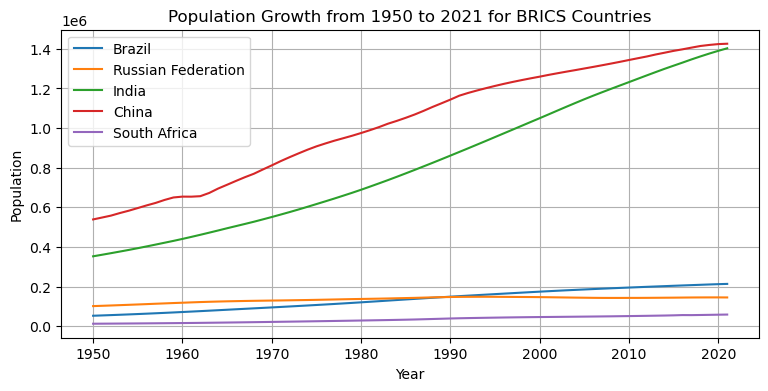

In [39]:
# Population over time

plt.figure(figsize=(9, 4)) 

for country in brics_countries: 
    country_data = dfBRICS[dfBRICS['Country'] == country] 
    plt.plot(country_data['Year'], country_data['Population_as_of_1_January'], label=country) 

plt.xlabel('Year') 
plt.ylabel('Population') 
plt.title('Population Growth from 1950 to 2021 for BRICS Countries') 
plt.legend() 
plt.grid(True)
plt.show()

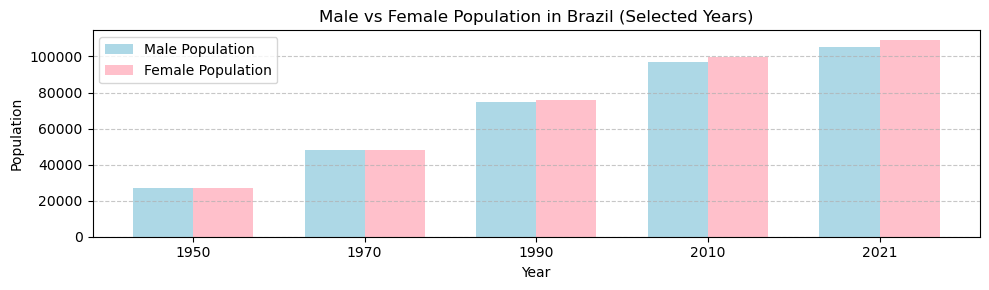

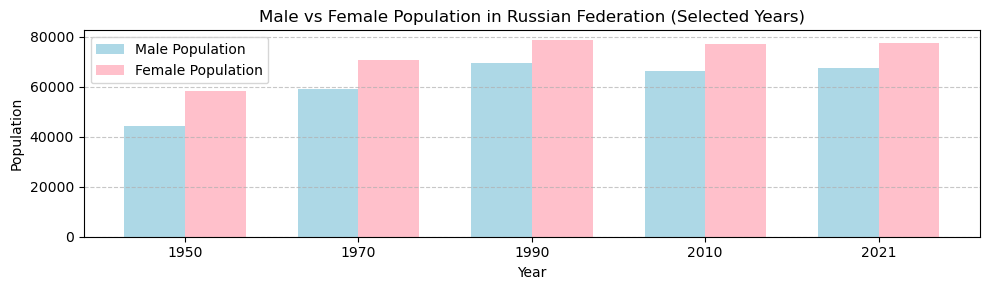

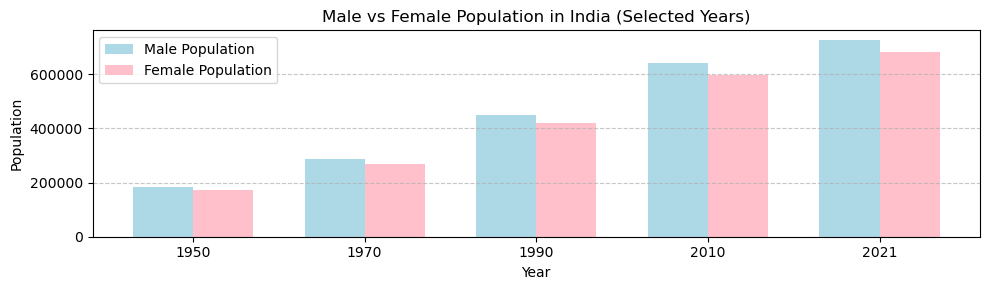

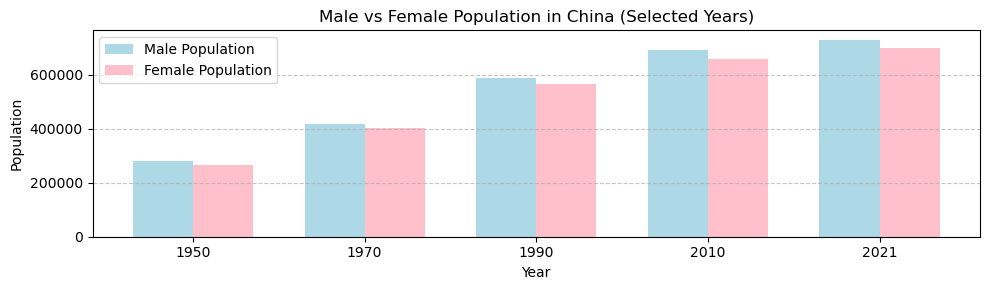

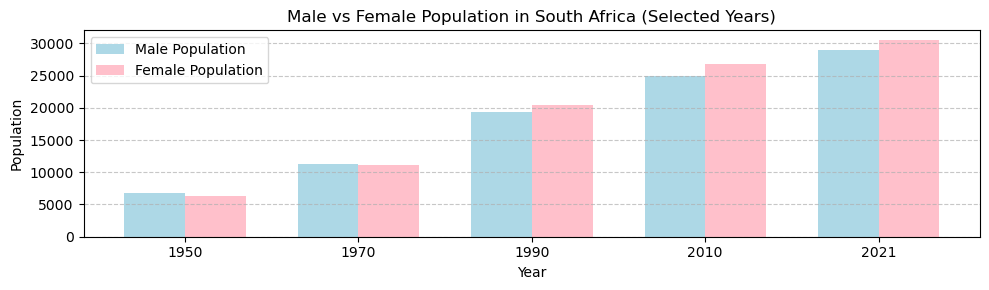

In [41]:

# Define the years 
years = [1950, 1970, 1990, 2010, 2021]

# Filter data for only these years
filtered_data = dfBRICS[dfBRICS['Year'].isin(years)]

# For each country, create a separate figure
for country in brics_countries:
    # Filter data for this country
    country_data = filtered_data[filtered_data['Country'] == country]
    
    # Create figure and axis
    plt.figure(figsize=(10, 3))
    
    # Setup for bar positions
    bar_width = 0.35
    index = np.arange(len(years))
    
    # Get male and female data for each year
    male_values = []
    female_values = []
    
    for year in years:
        year_data = country_data[country_data['Year'] == year]
        if not year_data.empty:
            male_values.append(year_data['Male_Population'].values[0])
            female_values.append(year_data['Female_Population'].values[0])
        else:
            male_values.append(0)
            female_values.append(0)
    
    # Create grouped bar chart
    plt.bar(index - bar_width/2, male_values, bar_width, color='lightblue', label='Male Population')
    plt.bar(index + bar_width/2, female_values, bar_width, color='pink', label='Female Population')
    
    # Set labels and title
    plt.xlabel('Year')
    plt.ylabel('Population')
    plt.title(f'Male vs Female Population in {country} (Selected Years)')
    plt.xticks(index, years)
    
    # Format y-axis to be more readable with millions/billions
    plt.ticklabel_format(style='plain', axis='y')
    
    # Add legend and show
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

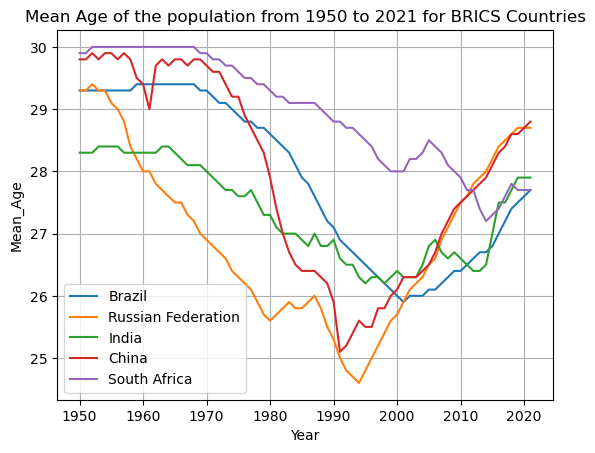

                  Country  Year  Population_as_of_1_January  Male_Population  \
14224              Brazil  1990                      149371            74926   
4576                China  1990                     1143767           587798   
5368                India  1990                      861205           449984   
8392   Russian Federation  1990                      147690            69351   
2920         South Africa  1990                       39303            19423   

       Female_Population  Mean_Age  Growth_Rate  
14224              75780      27.1       2735.0  
4576              565906      25.9      18705.0  
5368              420468      26.9      18384.0  
8392               78655      25.3        697.0  
2920               20455      28.8       1268.0  
       Mean_Age  Year
14184      29.3  1950
14185      29.3  1951
14186      29.3  1952
14187      29.3  1953
14188      29.3  1954
...         ...   ...
2947       27.6  2017
2948       27.8  2018
2949       27.7  2019

In [43]:
# Mean age over time

for country in brics_countries: 
    country_data = dfBRICS[dfBRICS['Country'] == country] 
    plt.plot(country_data['Year'], country_data['Mean_Age'], label=country) 

plt.xlabel('Year') 
plt.ylabel('Mean_Age') 
plt.title('Mean Age of the population from 1950 to 2021 for BRICS Countries') 
plt.legend() 
plt.grid(True)
plt.show()

testt = dfBRICS[dfBRICS['Year'] == 1990]
print(testt)
print(dfBRICS[['Mean_Age','Year']])

# Part 2: Functions and tools

## Moving-average trading strategy backtest
Backtest a strategy that buys a stock when its 12-period moving average crosses above its 24-period moving average and sells when it crosses back, trading at the next day's open. The data is daily prices for ANZ, CBA, BHP, RIO and WES from 2000 to 2022.

### Closing prices and correlations
Plot the closing prices over time and show a correlation heatmap, with comments on the relationships between the stocks.

In [46]:
# read all files 
dir = "Stock/"
filenames = np.sort(np.array(os.listdir(dir)))
print (filenames)

ANZ, BHP, CBA, RIO, WES = (pd.read_csv(dir + filename) for filename in filenames)

['ANZ.csv' 'BHP.csv' 'CBA.csv' 'RIO.csv' 'WES.csv']


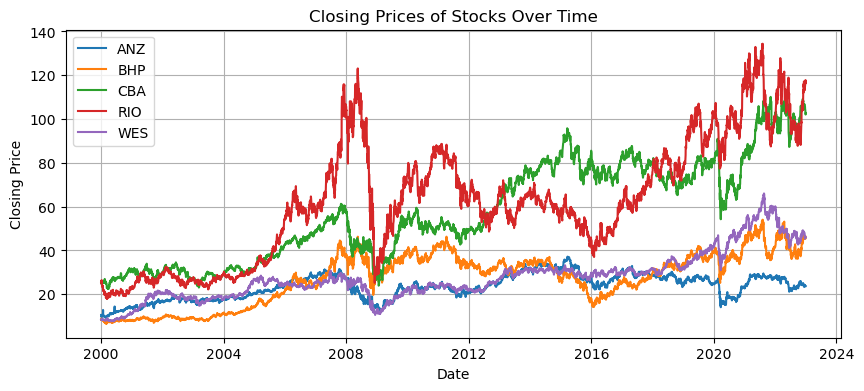

In [48]:
# Closing prices over time
dfstocks = [ANZ, BHP, CBA, RIO, WES]
stock_names = ['ANZ', 'BHP', 'CBA', 'RIO', 'WES']

for df in dfstocks: df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')
                                           
plt.figure(figsize=(10, 4))

for df, stock_name in zip(dfstocks, stock_names):
    plt.plot(df['Date'], df['Close'], label=stock_name)

plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.title('Closing Prices of Stocks Over Time')
plt.legend()
plt.grid(True)
plt.show()

          ANZ       BHP       CBA       RIO       WES
ANZ  1.000000  0.552427  0.739743  0.493755  0.560501
BHP  0.552427  1.000000  0.664872  0.922777  0.674817
CBA  0.739743  0.664872  1.000000  0.702151  0.836415
RIO  0.493755  0.922777  0.702151  1.000000  0.790591
WES  0.560501  0.674817  0.836415  0.790591  1.000000


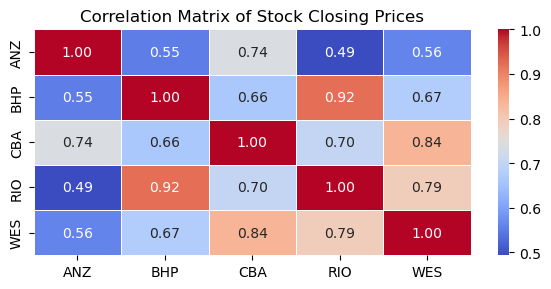

In [50]:
# Correlation heatmap of the closing prices
dfstocks = [ANZ, BHP, CBA, RIO, WES]
stock_names = ['ANZ', 'BHP', 'CBA', 'RIO', 'WES']
stock_dict = {name: df for name, df in zip(stock_names, dfstocks)}

#Extract 'Close' prices for each stock 
close_prices = pd.DataFrame()

for stock_name, df in stock_dict.items():
    close_prices[stock_name] = df['Close']

#Calculate the correlation matrix between the closing prices
correlation_matrix = close_prices.corr()
print(correlation_matrix)

plt.figure(figsize=(6, 3))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', cbar=True, linewidths=0.5)
plt.title("Correlation Matrix of Stock Closing Prices")
plt.tight_layout()

plt.show()

### Correlation Analysis of Stock Closing Prices

The correlation matrix above shows the **Pearson correlation coefficients** between the closing prices of five stocks: **ANZ, BHP, CBA, RIO, and WES**.

#### Key Observations:

- **High Correlations**:
  - `BHP` and `RIO`: **0.92** → Very strong positive correlation. Likely due to both being mining/resource companies, affected by similar market forces.
  - `CBA` and `WES`: **0.84** → Strong correlation, suggesting similar price trends, possibly due to both being part of the retail/consumer sector.
  - `CBA` and `ANZ`: **0.74** → Strong correlation, both are banks and move together due to similar economic drivers.
  - `RIO` and `WES`: **0.79** → Surprisingly strong, may suggest broader market alignment or shared macroeconomic exposure.

- **Moderate to Low Correlations**:
  - `ANZ` and `RIO`: **0.49** → Weak-moderate correlation, indicating more independent price movement.
  - `ANZ` and `BHP`: **0.55**, and `ANZ` with `WES`: **0.56** → Slight but not strong relationships.
  
#### Interpretation of the Heatmap:

- The heatmap uses the `coolwarm` color map:
  - Redder tones indicate stronger positive correlations (closer to +1).
  - Bluer tones indicate weaker correlations (closer to 0).
- Diagonal values are all `1.0`, representing perfect correlation with themselves.
- Stocks clustered with strong correlations might be part of the same industry or affected by similar economic events.

#### Conclusion:

- **BHP-RIO**, and **CBA-WES** show the strongest relationships.
- ANZ appears less correlated with others, indicating some diversification potential.
- Understanding these relationships helps with **portfolio diversification** and **risk management**.


### Moving averages and trades
Functions to calculate the moving averages, plot them against the daily open for 2015 to 2017, and record the buy and sell transactions (100 shares per trade, long only, open trades closed on the last day, no transaction costs).

In [54]:
# 12- and 24-period moving averages for each stock

def calculate_MA (stock, stock_name):
    # Calculate  moving average
    stock['12_MA'] = stock['Close'].rolling(window=12).mean()
    stock['24_MA'] = stock['Close'].rolling(window=24).mean()
    
    # Print last 5 values 
    print(f"\n{stock_name} - Last 5 values of 12-period moving average:")
    print(stock['12_MA'].tail())
    print(f"\n{stock_name} - Last 5 values of 24-period moving average:")
    print(stock['24_MA'].tail())
    
calculate_MA (ANZ,"ANZ")
calculate_MA (BHP,"BHP")
calculate_MA (CBA,"CBA")
calculate_MA (RIO,"RIO")
calculate_MA (WES,"WES")


ANZ - Last 5 values of 12-period moving average:
5818    23.838334
5819    23.841667
5820    23.850000
5821    23.846667
5822    23.856667
Name: 12_MA, dtype: float64

ANZ - Last 5 values of 24-period moving average:
5818    24.275417
5819    24.246667
5820    24.205833
5821    24.158750
5822    24.117500
Name: 24_MA, dtype: float64

BHP - Last 5 values of 12-period moving average:
5816    46.244167
5817    46.207500
5818    46.232500
5819    46.091667
5820    45.995000
Name: 12_MA, dtype: float64

BHP - Last 5 values of 24-period moving average:
5816    45.577917
5817    45.711667
5818    45.838750
5819    45.916667
5820    45.961667
Name: 24_MA, dtype: float64

CBA - Last 5 values of 12-period moving average:
5849    105.726668
5850    105.665834
5851    105.478334
5852    105.236668
5853    105.004168
Name: 12_MA, dtype: float64

CBA - Last 5 values of 24-period moving average:
5849    106.719167
5850    106.645834
5851    106.462501
5852    106.212917
5853    105.987501
Name: 24_M

['ANZ.csv' 'BHP.csv' 'CBA.csv' 'RIO.csv' 'WES.csv']
['ANZ', 'BHP', 'CBA', 'RIO', 'WES']


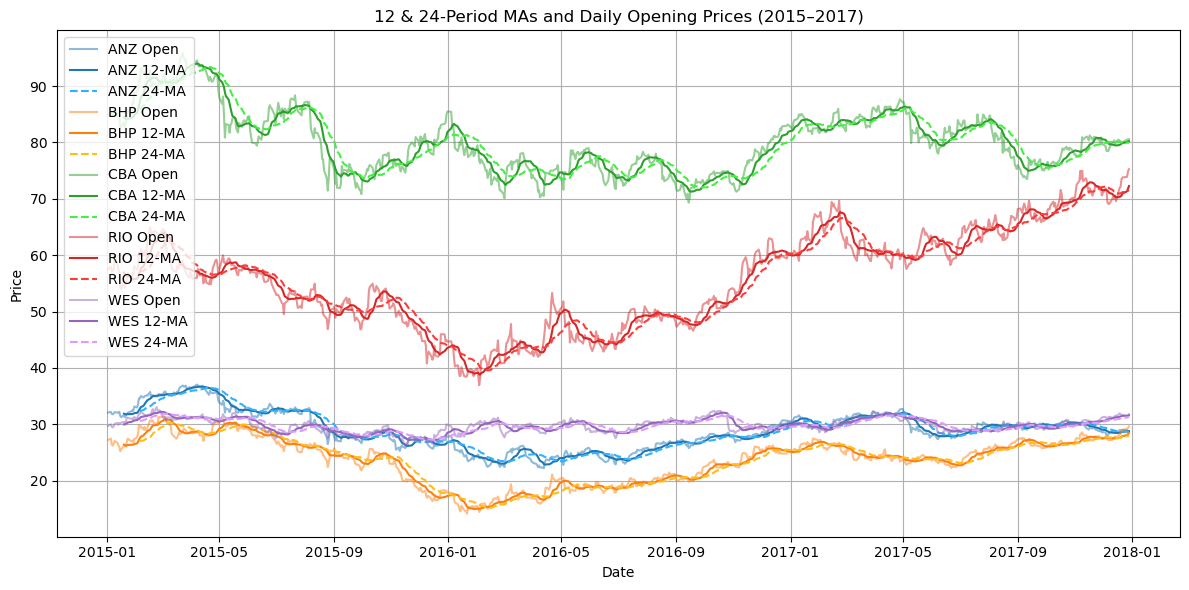

In [56]:
# Moving averages against the daily open price, 2015 to 2017

import matplotlib.colors as mcolors 

# Create a dictionary with stock and path for the function
print (filenames)
file_path= [dir + filename for filename in filenames]

print (stock_names)

csv_file_path = {stock: path for stock, path in zip(stock_names, file_path)}

def read_and_calculate_MA(csv_files):
    stock_dataframes = {}

    for stock_name, file_path in csv_files.items():
        df = pd.read_csv(file_path)

        # Convert 'Date' column to datetime
        df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')

        # Filter for the period 2015-2017
        df = df[(df['Date'] >= '2015-01-01') & (df['Date'] <= '2017-12-31')]

        # Calculate moving averages on 'Open' prices
        df['12_MA'] = df['Open'].rolling(window=12).mean()
        df['24_MA'] = df['Open'].rolling(window=24).mean()

        stock_dataframes[stock_name] = df

    return stock_dataframes


# Get a ligheter color to differenciate 12MA and 24MA
def adjust_color(color, factor):
    color_rgb = mcolors.hex2color(color)  # Convert hex to RGB
    adjusted_rgb = [min(1, c * factor) for c in color_rgb]  # Adjust RGB values
    return mcolors.rgb2hex(adjusted_rgb)  # Convert back to hex

# Function to plot the moving averages 
def plot_moving_averages(stock_dataframes):
    colors = plt.cm.tab10.colors
    plt.figure(figsize=(12, 6))

    for idx, (stock_name, df) in enumerate(stock_dataframes.items()):
        color = colors[idx % len(colors)]
        
        # Plot Opening Price
        plt.plot(df['Date'], df['Open'], label=f"{stock_name} Open", color=color, alpha=0.5)
        
        # Plot Moving Averages
        plt.plot(df['Date'], df['12_MA'], label=f"{stock_name} 12-MA", color=color)
        plt.plot(df['Date'], df['24_MA'], label=f"{stock_name} 24-MA", linestyle='--', color=adjust_color(color, 1.5))

    plt.title("12 & 24-Period MAs and Daily Opening Prices (2015–2017)")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

stock_dataMA = read_and_calculate_MA(csv_file_path)

plot_moving_averages(stock_dataMA)

In [58]:

# function that decide based on the condicions if, in each date, it should be selled or bought 
def buy_sell_transactions(df):
    transactions = []  
    position = None  

    for i in range(1, len(df)):
        prev_12, prev_24 = df['12_MA'].iloc[i - 1], df['24_MA'].iloc[i - 1]
        curr_12, curr_24 = df['12_MA'].iloc[i], df['24_MA'].iloc[i]

        # Buy signal: 12_MA crosses above 24_MA
        if curr_12 > curr_24 and prev_12 <= prev_24 and position is None:
            transactions.append({
                'Action': 'Buy',
                'Date': df['Date'].iloc[i],
                'Price': df['Open'].iloc[i],
                'Quantity': 100
            })
            position = 'buy'

        # Sell signal: 12_MA crosses below 24_MA
        elif curr_12 < curr_24 and prev_12 >= prev_24 and position == 'buy':
            transactions.append({
                'Action': 'Sell',
                'Date': df['Date'].iloc[i],
                'Price': df['Open'].iloc[i],
                'Quantity': 100
            })
            position = None

    # If still holding stock at end, sell
    if position == 'buy':
        transactions.append({
            'Action': 'Sell',
            'Date': df['Date'].iloc[-1],
            'Price': df['Open'].iloc[-1],
            'Quantity': 100
        })

    return transactions

# functins to print the first 10 transactions for each stock 
def print_first_10_transactions(stock_dataframes):
    for stock_name, df in stock_dataframes.items():
        transactions = buy_sell_transactions(df)
        
        print(f"\nFirst 10 transactions for {stock_name}:")
        
        for i, txn in enumerate(transactions[:10]):
            print(f"{i+1}. {txn['Action']} | Date: {txn['Date'].date()} | Price: ${txn['Price']:.2f} | Qty: {txn['Quantity']}")
        print("-" * 50)

print_first_10_transactions(stock_dataMA)


First 10 transactions for ANZ:
1. Buy | Date: 2015-06-25 | Price: $33.40 | Qty: 100
2. Sell | Date: 2015-07-13 | Price: $32.12 | Qty: 100
3. Buy | Date: 2015-07-30 | Price: $32.40 | Qty: 100
4. Sell | Date: 2015-08-07 | Price: $29.99 | Qty: 100
5. Buy | Date: 2015-09-23 | Price: $27.57 | Qty: 100
6. Sell | Date: 2015-09-29 | Price: $26.94 | Qty: 100
7. Buy | Date: 2015-10-15 | Price: $28.75 | Qty: 100
8. Sell | Date: 2015-11-05 | Price: $26.90 | Qty: 100
9. Buy | Date: 2015-11-30 | Price: $27.38 | Qty: 100
10. Sell | Date: 2015-12-15 | Price: $25.68 | Qty: 100
--------------------------------------------------

First 10 transactions for BHP:
1. Buy | Date: 2015-04-10 | Price: $28.03 | Qty: 100
2. Sell | Date: 2015-04-14 | Price: $27.05 | Qty: 100
3. Buy | Date: 2015-04-29 | Price: $30.33 | Qty: 100
4. Sell | Date: 2015-05-22 | Price: $29.49 | Qty: 100
5. Buy | Date: 2015-09-14 | Price: $24.10 | Qty: 100
6. Sell | Date: 2015-09-17 | Price: $24.65 | Qty: 100
7. Buy | Date: 2015-10-14 | 

### Trade log and performance
Build a data frame of all completed trades (stock, open and close date and price, quantity and profit), show its first and last rows, and summarise the profits per stock and in total, with a comment on whether the strategy is worth using.

In [61]:

# Very fimiliar to the buy_sell_transactions now it will create data frame with new columns that keep every transaction
def buy_sell_transactionsdf(df, stock_name):
    transactions = []  
    position = None  
    buy_price = None
    buy_date = None

    # Loop through the dataframe to identify buy and sell signals
    for i in range(1, len(df)):
        prev_12, prev_24 = df['12_MA'].iloc[i - 1], df['24_MA'].iloc[i - 1]
        curr_12, curr_24 = df['12_MA'].iloc[i], df['24_MA'].iloc[i]
        
        # Buy signal
        if curr_12 > curr_24 and prev_12 <= prev_24 and position is None:
            buy_price = df['Open'].iloc[i]
            buy_date = df['Date'].iloc[i]
            position = 'buy'

        # Sell signal
        elif curr_12 < curr_24 and prev_12 >= prev_24 and position == 'buy':
            sell_price = df['Open'].iloc[i]
            sell_date = df['Date'].iloc[i]
            profit = (sell_price - buy_price) * 100
            
            # Append the trade information to the transactions list
            transactions.append({
                'Stock': stock_name,
                'Open_Date': buy_date,
                'Close_Date': sell_date,
                'Open_Price': buy_price,
                'Close_Price': sell_price,
                'Quantity': 100,
                'Profit': profit
            })
            position = None  # Reset position after selling

    # If position is still open at the end of the data, close it at the last available price
    if position == 'buy':
        sell_price = df['Open'].iloc[-1]
        sell_date = df['Date'].iloc[-1]
        profit = (sell_price - buy_price) * 100
        transactions.append({
            'Stock': stock_name,
            'Open_Date': buy_date,
            'Close_Date': sell_date,
            'Open_Price': buy_price,
            'Close_Price': sell_price,
            'Quantity': 100,
            'Profit': profit
        })

    return transactions

# Define a wrapper function that aggregates trades for multiple stocks into a single DataFrame
def compile_all_trades(stock_data_dict):
    """
    stock_data_dict: dict where keys are stock names and values are their corresponding DataFrames
    """
    all_trades = []

    for stock_name, df in stock_data_dict.items():
        trades = buy_sell_transactionsdf(df, stock_name)
        all_trades.extend(trades)

    trades_df = pd.DataFrame(all_trades)
    return trades_df

all_trades_df = compile_all_trades(stock_dataMA)

# Reset index before printing, for a cleaner output
all_trades_df = all_trades_df.reset_index(drop=True)

# Print the first and last 10 rows
print(all_trades_df.head(10))
print(all_trades_df.tail(10))

  Stock  Open_Date Close_Date  Open_Price  Close_Price  Quantity      Profit
0   ANZ 2015-06-25 2015-07-13   33.400002    32.119999       100 -128.000260
1   ANZ 2015-07-30 2015-08-07   32.400002    29.990000       100 -241.000176
2   ANZ 2015-09-23 2015-09-29   27.570000    26.940001       100  -62.999916
3   ANZ 2015-10-15 2015-11-05   28.750000    26.900000       100 -185.000038
4   ANZ 2015-11-30 2015-12-15   27.379999    25.680000       100 -169.999885
5   ANZ 2016-01-04 2016-01-15   27.870001    25.450001       100 -242.000008
6   ANZ 2016-03-07 2016-04-04   25.209999    23.000000       100 -220.999908
7   ANZ 2016-04-27 2016-06-16   24.469999    23.389999       100 -107.999992
8   ANZ 2016-07-14 2016-09-15   24.549999    25.879999       100  132.999992
9   ANZ 2016-09-29 2016-11-03   27.719999    26.830000       100  -88.999939
   Stock  Open_Date Close_Date  Open_Price  Close_Price  Quantity      Profit
81   WES 2016-04-28 2016-05-27   30.281679    28.965084       100 -131.6595

In [63]:

# Create a dictionary to store individual DataFrames for each stock after the trade strategy  
trades_dataframes = {stock: df for stock, df in all_trades_df.groupby('Stock')}  

# Function to calculate each descriptive statistics
def calculate_statistics(stock_df, stock_name):
    stats = {}
    stats['Sum'] = stock_df['Profit'].sum()
    stats['Number of Trades'] = stock_df['Profit'].count()
    stats['Mean'] = stock_df['Profit'].mean()
    stats['Median'] = stock_df['Profit'].median()
    stats['Standard Deviation'] = stock_df['Profit'].std()
    stats['Max'] = stock_df['Profit'].max()
    stats['Min'] = stock_df['Profit'].min()
    
    print(f"\nStatistics for {stock_name}:")
    for key, value in stats.items():
        print(f"{key}: {value}")
    return stats

statistics = {}

# Applying the calculate_statistics for each stock 

for stock_name, df in trades_dataframes.items():
    statistics[stock_name] = calculate_statistics(df, stock_name)

# Combine all trading profits into a single DataFrame
all_profits = pd.concat([df['Profit'] for df in trades_dataframes.values()], ignore_index=True)

# Calculate statistics for total trading profits
total_stats = {
    'Sum': all_profits.sum(),
    'Number of Trades': all_profits.count(),
    'Mean': all_profits.mean(),
    'Median': all_profits.median(),
    'Standard Deviation': all_profits.std(),
    'Max': all_profits.max(),
    'Min': all_profits.min()
}

print("\nStatistics for Total Trading Profits:")
for key, value in total_stats.items():
    print(f"{key}: {value}")

# Analyze the strategy
if total_stats['Sum'] > 0:
    print("\nThis strategy was profitable overall.")
else:
    print("\nThis strategy was not profitable overall.")

# Print conclusion about the strategy
print("Mean Profit:", total_stats['Mean'].round(2))
print("Standard Deviation of Profits:", round(total_stats['Standard Deviation'],2))


Statistics for ANZ:
Sum: -1147.0001229999987
Number of Trades: 19
Mean: -60.36842752631572
Median: -62.999916000000056
Standard Deviation: 131.92390159106446
Max: 217.00000700000004
Min: -242.00000799999975

Statistics for BHP:
Sum: -506.31303999999915
Number of Trades: 19
Mean: -26.64805473684206
Median: -39.99996199999991
Standard Deviation: 141.692851552239
Max: 169.00005399999998
Min: -318.99995800000005

Statistics for CBA:
Sum: -1539.1571040000001
Number of Trades: 17
Mean: -90.53865317647059
Median: -22.000122000000033
Standard Deviation: 286.42639147624453
Max: 569.0002440000001
Min: -558.0001830000001

Statistics for RIO:
Sum: -1110.0002289999998
Number of Trades: 18
Mean: -61.66667938888887
Median: 37.49961800000037
Standard Deviation: 381.2942154981317
Max: 929.0000919999998
Min: -625.0

Statistics for WES:
Sum: -1134.4062809999991
Number of Trades: 18
Mean: -63.022571166666616
Median: -65.11821749999989
Standard Deviation: 97.63773830535843
Max: 128.8127900000003
Min: -255

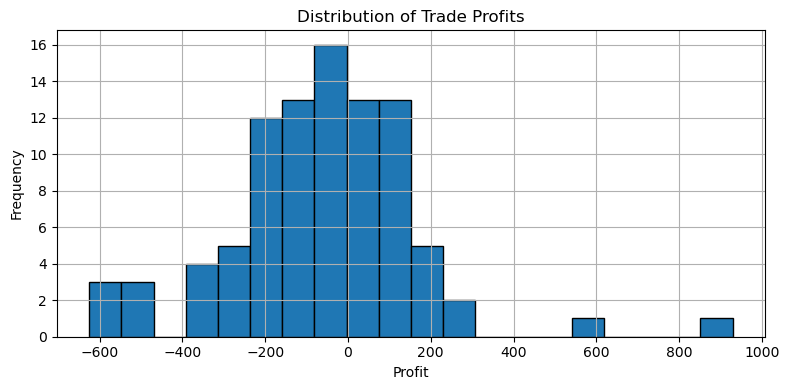

In [65]:
# This will give Jim a visual intuition about profit spread and outliers:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.hist(all_profits, bins=20, edgecolor='black')
plt.title("Distribution of Trade Profits")
plt.xlabel("Profit")
plt.ylabel("Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()



Descriptive Statistics by Stock:
         Sum  Number of Trades   Mean  Median  Standard Deviation     Max  \
ANZ -1147.00              19.0 -60.37  -63.00              131.92  217.00   
BHP  -506.31              19.0 -26.65  -40.00              141.69  169.00   
CBA -1539.16              17.0 -90.54  -22.00              286.43  569.00   
RIO -1110.00              18.0 -61.67   37.50              381.29  929.00   
WES -1134.41              18.0 -63.02  -65.12               97.64  128.81   

        Min  
ANZ -242.00  
BHP -319.00  
CBA -558.00  
RIO -625.00  
WES -255.49  


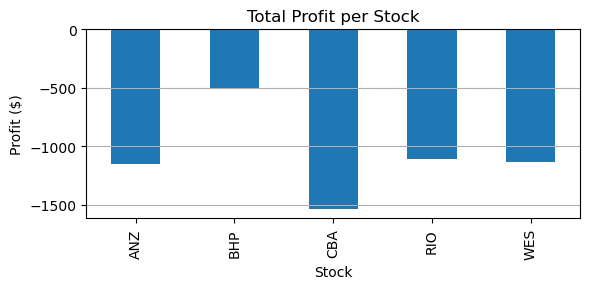

In [67]:
# Present statistics as a DataFrame - makes stats much easier to compare
statistics_df = pd.DataFrame(statistics).T  # Transpose so each stock is a row
print("\nDescriptive Statistics by Stock:")
print(statistics_df.round(2))

# Total profit per stock bar chart
statistics_df['Sum'].plot(kind='bar', title='Total Profit per Stock', ylabel='Profit ($)', xlabel='Stock', figsize=(6, 3))
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()



### **Performance Comments:** 

The trading strategy based on the **12-period and 24-period** moving average crossover resulted in **consistent losses across all five stocks analyzed**. Despite some positive trades, the overall sum of profits was negative, and the standard deviation of returns was often higher than the mean, suggesting a poor return-to-risk profile. 

As it stands, this strategy is not suitable for real-world implementation. Jim should consider attending some Business Analytics Coding classes and optimizing the strategy parameters, introducing risk controls, or exploring alternative signals before deploying this method in a live trading environment.